In [ ]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv
import os
load_dotenv(override=True)


True

In [37]:
class CricketState(TypedDict):
        balls:0
        runs_without_boundry:0
        total_runs:0
        fours:0
        sixes:0
        Sr:0.0
        runs_per_boundry:0.0
        balls_per_boundry:0.0
        summary:str

In [38]:
# api_key = os.environ.get("OPENROUTER_API_KEY")
api_key = os.getenv("OPENROUTER_API_KEY")


llm = ChatOpenAI(
      model="openrouter/free",
       base_url="https://openrouter.ai" + "/api/v1",
       api_key=api_key,
       temperature=0,
       max_tokens=300,
       max_retries=3,
)

In [39]:
# WRONG: Returning the whole state causes concurrent updates on 'balls', 'fours', etc.
# def calculate_runs(state: CricketState):
#     state["total_runs"] = state["runs_without_boundry"] + (state["fours"] * 4) + (state["sixes"] * 6)
#     return state

# RIGHT: Return ONLY the specific key this node computes
def calculate_runs(state: CricketState):
    total_runs = state["runs_without_boundry"] + (state["fours"] * 4) + (state["sixes"] * 6)
    return {"total_runs": total_runs}

def calculate_boundaries_per_ball(state: CricketState):
    boundaries = state["fours"] + state["sixes"]
    balls_per_boundry = state["balls"] / boundaries if boundaries > 0 else 0.0
    return {"balls_per_boundry": balls_per_boundry}

def calculate_sr(state: CricketState):
    total_runs = state["runs_without_boundry"] + (state["fours"] * 4) + (state["sixes"] * 6)
    sr = (total_runs / state["balls"]) * 100 if state["balls"] > 0 else 0.0
    return {"Sr": sr}

def calculate_runs_per_boundry(state: CricketState):
    boundaries = state["fours"] + state["sixes"]
    boundary_runs = (state["fours"] * 4) + (state["sixes"] * 6)
    runs_per_boundry = boundary_runs / boundaries if boundaries > 0 else 0.0
    return {"runs_per_boundry": runs_per_boundry}

def summary(state: CricketState):
    prompt = (
        f"Summarize this cricket innings in 2 short sentences: "
        f"Total Runs: {state['total_runs']} | Strike Rate: {state['Sr']:.2f} | "
        f"Runs/Boundary: {state['runs_per_boundry']:.2f} | Balls/Boundary: {state['balls_per_boundry']:.2f}"
    )

    result = llm.invoke(prompt).content  # Extract .content string
    return {"summary": result}


In [40]:

graph = StateGraph(CricketState)

# 1. Register each node individually
graph.add_node("calculate_runs", calculate_runs)
graph.add_node("calculate_boundaries_per_ball", calculate_boundaries_per_ball)
graph.add_node("calculate_sr", calculate_sr)
graph.add_node("calculate_runs_per_boundry", calculate_runs_per_boundry)
graph.add_node("summary", summary)

# 2. Fan-out: Connect START to all 4 parallel nodes
graph.add_edge(START, "calculate_runs")
graph.add_edge(START, "calculate_boundaries_per_ball")
graph.add_edge(START, "calculate_sr")
graph.add_edge(START, "calculate_runs_per_boundry")

# 3. Fan-in: Connect all 4 parallel nodes to summary
graph.add_edge("calculate_runs", "summary")
graph.add_edge("calculate_boundaries_per_ball", "summary")
graph.add_edge("calculate_sr", "summary")
graph.add_edge("calculate_runs_per_boundry", "summary")

# 4. Connect summary to END
graph.add_edge("summary", END)

# Compile the graph
workflow = graph.compile()


In [41]:
output = workflow.invoke({
  "balls": 45,
  "runs_without_boundry": 28,
  "total_runs": 0,
  "fours": 6,
  "sixes": 2,
  "Sr": 0.0,
  "runs_per_boundry": 0.0,
  "balls_per_boundry": 0.0,
  "summary": ""
}
)


print("summary ",output["summary"])

summary  The batsman amassed 64 runs at a strike rate of 142.22, showcasing a brisk and attacking approach. He averaged 4.5 runs per boundary, meaning he struck a boundary roughly every 5.6 balls, underscoring his aggressive strokeplay.


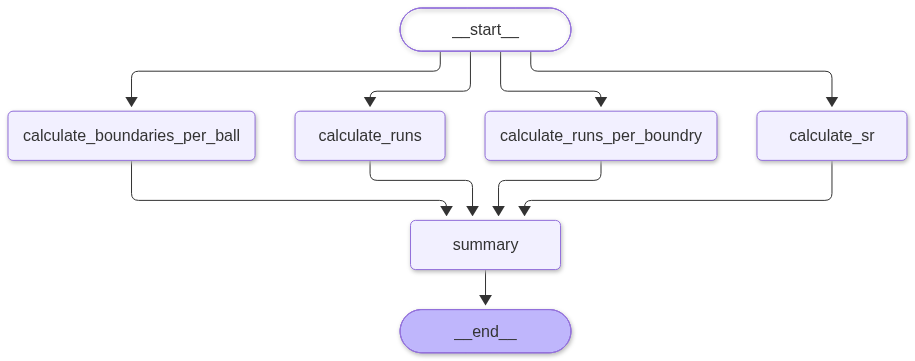

In [42]:
from IPython.display import display, Markdown , Image
# display(Markdown("### Output of the workflow execution  Bmi: {}".format(output["bmi"])))

Image(workflow.get_graph().draw_mermaid_png())